# Tweet Emotion Detection

This notebook compares Bag of Words (BoW), TF-IDF, and Word2Vec text representations with Logistic Regression and Linear SVM classifiers for TweetEval emotion classification. It tunes four BoW/TF-IDF classifier combinations and compares them with a word-plus-character TF-IDF model, selects a model using validation macro F1, and evaluates it on the official test split.

**Environment:** Use the project .venv313 Python 3.13 kernel. It includes Gensim and NLTK. The NLP setup cell downloads WordNet and the English POS tagger to NLTK's standard data folder.


## 1. Load the dataset

In [49]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")

In [50]:
print(dataset)
print(f"Train: {len(dataset['train']):,} | Validation: {len(dataset['validation']):,} | Test: {len(dataset['test']):,}")

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# Define the label map once and reuse it in charts and evaluation.
emotion_labels = {0: "anger", 1: "joy", 2: "optimism", 3: "sadness"}
for frame in (train_df, val_df, test_df):
    frame["emotion"] = frame["label"].map(emotion_labels)

display(train_df.head())

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3257
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})
Train: 3,257 | Validation: 374 | Test: 1,421


,text,label,emotion
0,“Worry is a down payment on a problem you may ...,2,optimism
1,My roommate: it's okay that we can't spell bec...,0,anger
2,No but that's so cute. Atsu was probably shy a...,1,joy
3,Rooneys fucking untouchable isn't he? Been fuc...,0,anger
4,it's pretty depressing when u hit pan on ur fa...,3,sadness


## 2. Exploratory Data Analysis

In [51]:
sns.set_theme(style="whitegrid")
# Dataset overview and data quality by split.
dataset_splits = {"train": train_df, "validation": val_df, "test": test_df}
overview = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "duplicate_tweets": int(frame["text"].duplicated().sum()),
    }
    for name, frame in dataset_splits.items()
])
display(overview)
print("Training columns and types:")
display(train_df.dtypes.to_frame("dtype"))
print("Training examples:")
display(train_df[["text", "emotion"]].sample(5))

,split,rows,missing_cells,duplicate_rows,duplicate_tweets
0,train,3257,0,25,25
1,validation,374,0,0,0
2,test,1421,0,0,0


Training columns and types:


,dtype
text,str
label,int64
emotion,str


Training examples:


,text,emotion
2869,So I wished my sis 12 midnight but received no...,sadness
3254,@user @user @user @user @user as a fellow UP g...,anger
1613,🍃When #life shows you have a hundred reasons t...,optimism
661,Do not grow weary in doing good.'\n\n-@billcli...,optimism
55,@user @user Prudence suggests that a 8+% bump ...,anger


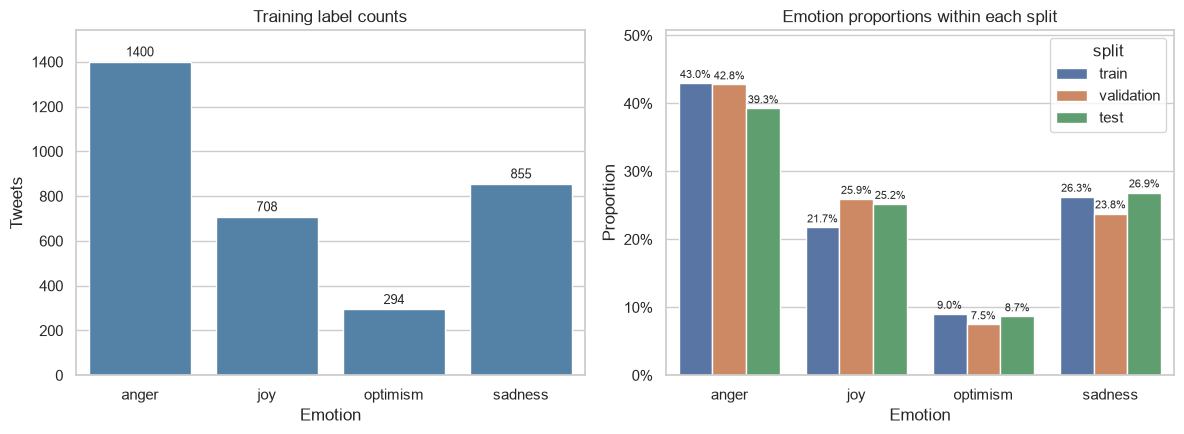

In [52]:
# Compare emotion counts and within-split proportions across the official splits.
from matplotlib.ticker import PercentFormatter

label_names = list(emotion_labels.values())
counts = pd.DataFrame({
    name: frame["emotion"].value_counts().reindex(label_names, fill_value=0)
    for name, frame in dataset_splits.items()
})
proportions = counts.div(counts.sum(axis=0), axis=1).rename_axis("emotion").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(
    data=train_df, x="emotion", order=label_names,
    ax=axes[0], color="steelblue",
)
axes[0].set(title="Training label counts", xlabel="Emotion", ylabel="Tweets")
axes[0].margins(y=0.10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=2, fontsize=9)

proportion_data = proportions.melt(
    id_vars="emotion", var_name="split", value_name="proportion"
)
sns.barplot(
    data=proportion_data, x="emotion", y="proportion", hue="split",
    order=label_names, ax=axes[1],
)
axes[1].set(
    title="Emotion proportions within each split",
    xlabel="Emotion",
    ylabel="Proportion",
)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].margins(y=0.18)
for container in axes[1].containers:
    labels = [f"{bar.get_height():.1%}" for bar in container]
    axes[1].bar_label(container, labels=labels, padding=2, fontsize=8)

plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
emotion,,,,,,,,
anger,1400.0,16.7,6.5,1.0,12.0,18.0,22.0,32.0
joy,708.0,15.2,6.6,1.0,9.0,15.0,21.0,30.0
optimism,294.0,17.3,6.1,3.0,12.0,18.0,22.0,31.0
sadness,855.0,15.7,7.0,2.0,10.0,16.0,22.0,33.0


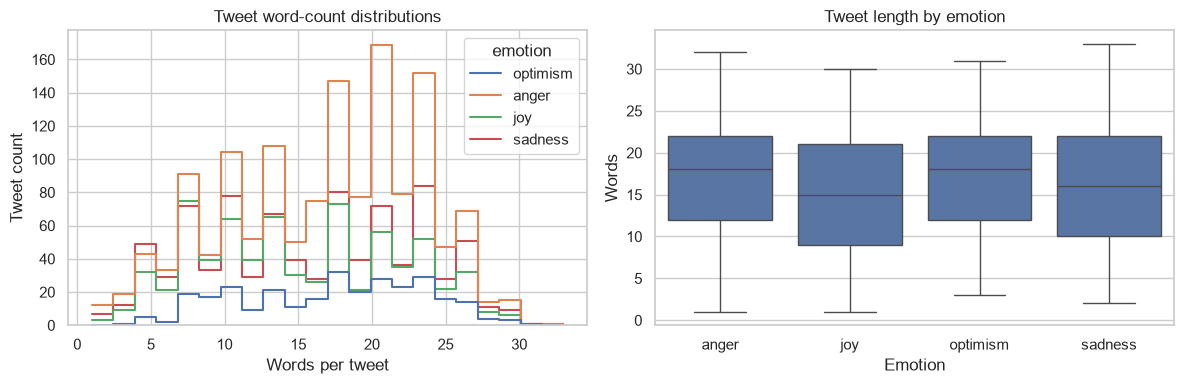

In [53]:
# Tweet length by words and characters.
train_df["word_count"] = train_df["text"].astype(str).str.split().str.len()
# train_df["char_count"] = train_df["text"].astype(str).str.len()
display(train_df.groupby("emotion")["word_count"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=train_df, x="word_count", hue="emotion", stat="count",
             element="step", fill=False, ax=axes[0])
sns.boxplot(data=train_df, x="emotion", y="word_count", order=label_names, ax=axes[1])
axes[0].set(title="Tweet word-count distributions", xlabel="Words per tweet", ylabel="Tweet count")
axes[1].set(title="Tweet length by emotion", xlabel="Emotion", ylabel="Words")
plt.tight_layout()
plt.show()

### Word frequencies and word clouds

Frequencies below are calculated from training tweets only. The light cleanup removes links and usernames while retaining hashtag words.

,word,count
0,i,1529
1,the,1517
2,to,1209
3,a,1066
4,and,887
5,of,747
6,you,739
7,is,738
8,it,645
9,in,574


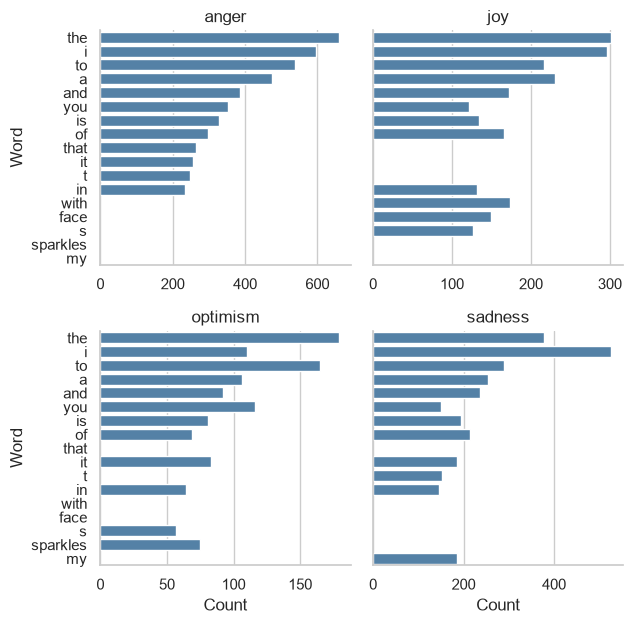

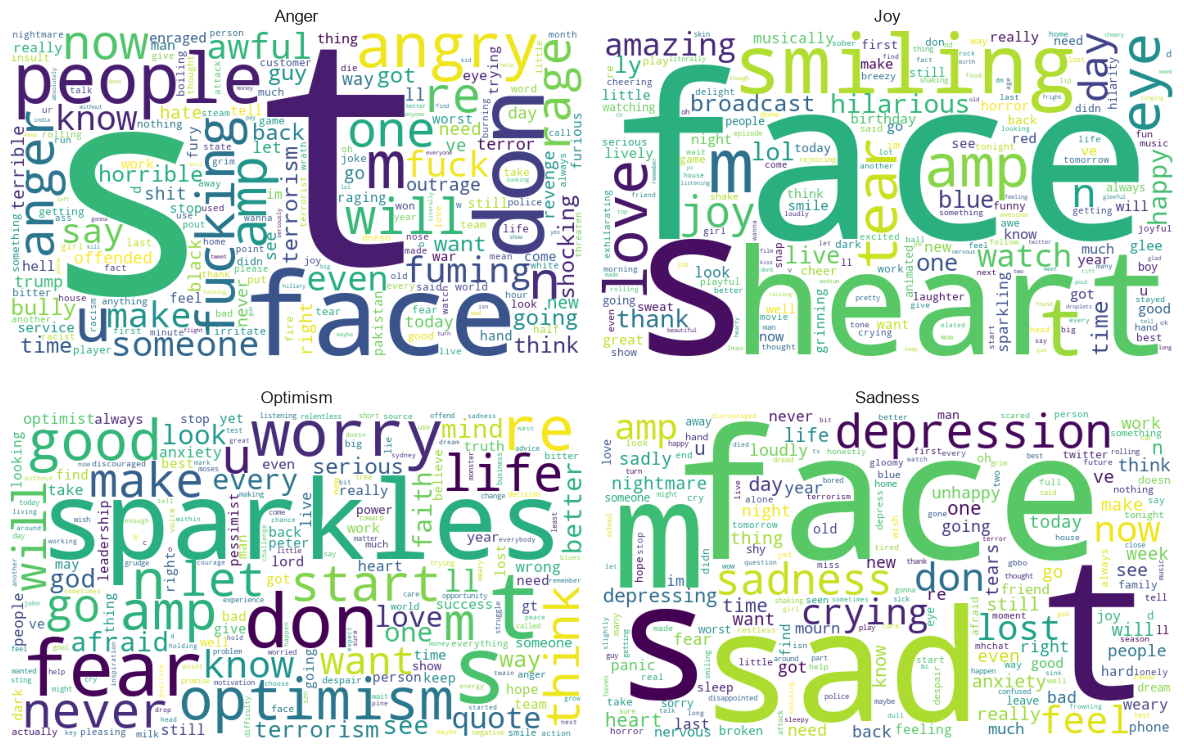

In [54]:
import re
from collections import Counter

def words_for_eda(text):
    text = emoji.demojize(str(text).lower())
    text = re.sub(r"https?://\S+|www\.\S+|(?<!\w)@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return re.findall(r"[a-z]+", text)

word_counts = Counter(word for tweet in train_df["text"] for word in words_for_eda(tweet))
display(pd.DataFrame(word_counts.most_common(20), columns=["word", "count"]))

# Top words for each emotion.
top_words = []
for emotion in label_names:
    words = Counter(word for tweet in train_df.loc[train_df["emotion"].eq(emotion), "text"]
                    for word in words_for_eda(tweet))
    top_words.extend({"emotion": emotion, "word": word, "count": count}
                     for word, count in words.most_common(12))
top_words = pd.DataFrame(top_words)
grid = sns.catplot(data=top_words, x="count", y="word", col="emotion", col_order=label_names,
                   col_wrap=2, kind="bar", sharex=False, height=3.2, color="steelblue")
grid.set_titles("{col_name}")
grid.set_axis_labels("Count", "Word")
plt.show()

from wordcloud import WordCloud

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, emotion in zip(axes.flat, label_names):
    text = " ".join(word for tweet in train_df.loc[train_df["emotion"].eq(emotion), "text"]
                    for word in words_for_eda(tweet))
    ax.imshow(WordCloud(width=700, height=400, background_color="white",
                        collocations=False).generate(text))
    ax.set_title(emotion.title())
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Clean, normalize, tokenize, and lemmatize

This follows Lab1: NLTK's WordNet lemmatizer uses POS tags to choose the correct base form. The setup cell downloads WordNet, OMW, and the English POS tagger to NLTK's standard user data location; no Project/nltk_data folder is created.

The cleaner retains hashtag words, emoji and emoticons, negations, intensity and contrast words. It converts emphasis punctuation to text cues, normalizes repeated characters, removes URLs, HTML tags and mentions, tokenizes, optionally removes stopwords, and lemmatizes.


### Remove duplicate training tweets

The overview above describes the raw splits. Remove exact repeated tweet text from training before tokenization so duplicates do not receive extra weight. Keep validation and test unchanged.


In [55]:
duplicate_label_counts = train_df.groupby("text")["label"].nunique()
if duplicate_label_counts.gt(1).any():
    raise ValueError("Repeated training tweets have conflicting labels review them before deduplication.")

train_rows_before = len(train_df)
train_df = train_df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
dataset_splits["train"] = train_df
removed_duplicates = train_rows_before - len(train_df)
print(f"Removed {removed_duplicates} duplicate training tweets; train rows now: {len(train_df):,}.")


Removed 25 duplicate training tweets; train rows now: 3,232.


### Check for exact tweet overlap across splits

After removing repeated training tweets, check that no exact tweet text is shared between train, validation, and test.


In [56]:
# Exact text overlap across the official splits can indicate duplicate leakage.
split_pairs = (("train", "validation"), ("train", "test"), ("validation", "test"))
overlap_rows = []
for left_name, right_name in split_pairs:
    left_texts = set(dataset_splits[left_name]["text"])
    right_texts = set(dataset_splits[right_name]["text"])
    overlap_rows.append({
        "Split pair": f"{left_name} / {right_name}",
        "Shared exact tweets": len(left_texts & right_texts),
    })

split_overlap = pd.DataFrame(overlap_rows)
display(split_overlap)
if split_overlap["Shared exact tweets"].gt(0).any():
    raise ValueError("Exact tweet text appears in more than one split; review the overlap before modeling.")


,Split pair,Shared exact tweets
0,train / validation,0
1,train / test,0
2,validation / test,0


In [57]:
import nltk
from nltk.stem import WordNetLemmatizer

required_nltk_resources = (
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger_eng",
)
for resource in required_nltk_resources:
    nltk.download(resource, quiet=False)

lemmatizer = WordNetLemmatizer()
print("NLTK data search locations:")
for location in nltk.data.path:
    print(" -", location)
print("WordNet check:", lemmatizer.lemmatize("cars"))
print("POS tagger check:", nltk.pos_tag(["running"]))


NLTK data search locations:
 - C:\Users\panha/nltk_data
 - d:\NLP-Lab\.venv313\nltk_data
 - d:\NLP-Lab\.venv313\share\nltk_data
 - d:\NLP-Lab\.venv313\lib\nltk_data
 - C:\Users\panha\AppData\Roaming\nltk_data
 - C:\nltk_data
 - D:\nltk_data
 - E:\nltk_data
WordNet check: car
POS tagger check: [('running', 'VBG')]


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [58]:
import html
import re
import unicodedata
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

lemmatizer = WordNetLemmatizer()
tweet_tokenizer = TweetTokenizer(preserve_case=False)
keep_words = {
    "no", "nor", "not", "never", "very", "too", "so", "more", "most", "less",
    "but", "however", "yet", "up", "down",
}
stop_words = set(ENGLISH_STOP_WORDS) - keep_words

contractions = {
    "can't": "can not",
    "won't": "will not",
    "shan't": "shall not",
    "ain't": "not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "hasn't": "has not",
    "haven't": "have not",
    "hadn't": "had not",
    "couldn't": "could not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "mustn't": "must not",
    "needn't": "need not",
    "mightn't": "might not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "i've": "i have",
    "you've": "you have",
    "we've": "we have",
    "they've": "they have",
    "i'll": "i will",
    "you'll": "you will",
    "he'll": "he will",
    "she'll": "she will",
    "it'll": "it will",
    "we'll": "we will",
    "they'll": "they will",
    "let's": "let us",
}
contraction_pattern = re.compile(
    r"\b(?:" + "|".join(
        re.escape(item) for item in sorted(contractions, key=len, reverse=True)
    ) + r")\b",
    flags=re.IGNORECASE,
)

# Convert common ASCII emoticons before removing punctuation.
emoticon_variants = {
    "emoticon_broken_heart": ["</3"],
    "emoticon_heart": ["<3"],
    "emoticon_wink": [";)", ";-)", ";]", ";-]"],
    "emoticon_playful": [":p", ":-p", ";p", ";-p"],
    "emoticon_positive": [":)", ":-)", ":]", ":-]", ":d", ":-d", "=)", "=-)", "(:", "(-:"],
    "emoticon_negative": [":(", ":-(", ":[", ":-[", "=(", "=-(", ":'(", ":'-(", "):", ")-:"],
    "emoticon_neutral": [":|", ":-|", ":/", ":-/", ":\\", ":-\\", ":o", ":-o"],
}
emoticon_map = {
    variant.lower(): label
    for label, variants in emoticon_variants.items()
    for variant in variants
}
emoticon_pattern = re.compile(
    r"(?<![A-Za-z0-9])(?:" + "|".join(
        re.escape(item) for item in sorted(emoticon_map, key=len, reverse=True)
    ) + r")(?![A-Za-z0-9])",
    flags=re.IGNORECASE,
)

def clean_tweet(text):
    text = html.unescape(str(text))
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = contraction_pattern.sub(
        lambda match: contractions[match.group(0).lower()], text
    )
    text = emoticon_pattern.sub(
        lambda match: f" {emoticon_map[match.group(0).lower()]} ", text
    )
    text = emoji.demojize(text)
    # Remove HTML tags such as <br> and <b>.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove links that start with http://, https://, or www.
    # The URL match continues until whitespace.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove @mentions made of letters, digits, or underscores.
    # (?<!\w) prevents matching an @ that appears inside another word.
    text = re.sub(r"(?<!\w)@\w+", " ", text)

    # Remove the # symbol but keep the hashtag words for classification.
    # Split hashtags at lowercase-to-uppercase boundaries,
    # so #SoHappy becomes "So Happy".
    text = re.sub(
        r"#(\w+)",
        lambda match: re.sub(r"([a-z])([A-Z])", r"\1 \2", match.group(1)),
        text,
    )

    # Preserve expressive punctuation as words before removing punctuation.
    text = re.sub(r"!+", " exclamation_mark ", text)
    text = re.sub(r"\?+", " question_mark ", text)
    text = re.sub(r"\.{2,}", " ellipsis ", text)

    # Limit any run of 3+ identical characters to two,
    # reducing stretched spellings while retaining emphasis (soooo -> soo).
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)

    text = text.lower()
    return "".join(
        " " if unicodedata.category(char).startswith("P") and char != "_" else char
        for char in text
    ).strip()


def wordnet_pos(penn_tag):
    """Map a Penn Treebank tag to the WordNet POS labels."""
    if penn_tag.startswith("J"):
        return "a"
    if penn_tag.startswith("V"):
        return "v"
    if penn_tag.startswith("R"):
        return "r"
    return "n"


def tokenize_normalize(text, remove_stopwords=False, lemmatize=True):
    tokens = tweet_tokenizer.tokenize(clean_tweet(text))

    if remove_stopwords:
        tokens = [
            token for token in tokens
            if not (token.isalpha() and token in stop_words)
        ]

    # POS-tag regular words and preserve emoji/emoticon placeholders.
    word_positions = [i for i, token in enumerate(tokens) if token.isalpha()]
    if lemmatize and word_positions:
        tagged_words = nltk.pos_tag([tokens[i] for i in word_positions])
        for index, (word, tag) in zip(word_positions, tagged_words):
            tokens[index] = lemmatizer.lemmatize(word, wordnet_pos(tag))

    return tokens


example = "@user I am sooo happy!!! #GreatDay https://example.com 😄 :) :( :D <3 </3"
print("Cleaned:", clean_tweet(example))
print("Lemmatized tokens:", tokenize_normalize(example))


Cleaned: i am soo happy exclamation_mark  great day   grinning_face_with_smiling_eyes   emoticon_positive  emoticon_negative  emoticon_positive  emoticon_heart  emoticon_broken_heart
Lemmatized tokens: ['i', 'be', 'soo', 'happy', 'exclamation_mark', 'great', 'day', 'grinning_face_with_smiling_eyes', 'emoticon_positive', 'emoticon_negative', 'emoticon_positive', 'emoticon_heart', 'emoticon_broken_heart']


In [59]:
# Use WordNet-lemmatized tokens for the main models and retain variants for comparison.
for frame in dataset_splits.values():
    frame["tokens"] = frame["text"].map(tokenize_normalize)
    frame["tokens_no_stopwords"] = frame["text"].map(
        lambda text: tokenize_normalize(text, remove_stopwords=True)
    )
    frame["tokens_unlemmatized"] = frame["text"].map(
        lambda text: tokenize_normalize(text, lemmatize=False)
    )

display(train_df[
    ["text", "tokens", "tokens_no_stopwords", "tokens_unlemmatized", "emotion"]
].head())


,text,tokens,tokens_no_stopwords,tokens_unlemmatized,emotion
0,“Worry is a down payment on a problem you may ...,"[worry, be, a, down, payment, on, a, problem, ...","[worry, down, payment, problem, never, joyce, ...","[worry, is, a, down, payment, on, a, problem, ...",optimism
1,My roommate: it's okay that we can't spell bec...,"[my, roommate, it, s, okay, that, we, can, not...","[roommate, s, okay, not, spell, autocorrect, t...","[my, roommate, it, s, okay, that, we, can, not...",anger
2,No but that's so cute. Atsu was probably shy a...,"[no, but, that, s, so, cute, atsu, be, probabl...","[no, but, s, so, cute, atsu, probably, shy, ph...","[no, but, that, s, so, cute, atsu, was, probab...",joy
3,Rooneys fucking untouchable isn't he? Been fuc...,"[rooneys, fuck, untouchable, be, not, he, ques...","[rooneys, fuck, untouchable, not, question_mar...","[rooneys, fucking, untouchable, is, not, he, q...",anger
4,it's pretty depressing when u hit pan on ur fa...,"[it, s, pretty, depress, when, u, hit, pan, on...","[s, pretty, depress, u, hit, pan, ur, favourit...","[it, s, pretty, depressing, when, u, hit, pan,...",sadness


## 4. Compare preprocessing options

Use the validation split to compare lemmatization and stopword removal with the same TF-IDF and Logistic Regression baseline. Select the token version by macro F1; keep the test split for final evaluation only.


In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def identity_tokenizer(tokens):
    return tokens

def metric_scores(y_true, y_pred):
    scores = {"Accuracy": accuracy_score(y_true, y_pred)}
    for average in ("macro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        scores.update({
            f"Precision ({average})": precision,
            f"Recall ({average})": recall,
            f"F1-score ({average})": f1,
        })
    return scores


def fit_and_score(model, X_train, y_train, X_eval, y_eval):
    """Fit a classifier, predict the evaluation split, and return all metrics."""
    model.fit(X_train, y_train)
    predictions = model.predict(X_eval)
    return model, metric_scores(y_eval, predictions)


def make_tfidf():
    return TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True,
    )

preprocessing_options = [
    ("Lemmatization; stopwords kept", "tokens"),
    ("Lemmatization; stopwords removed", "tokens_no_stopwords"),
    ("No lemmatization; stopwords kept", "tokens_unlemmatized"),
]
preprocessing_results = []
for name, token_column in preprocessing_options:
    vectorizer = make_tfidf()
    X_train = vectorizer.fit_transform(train_df[token_column].tolist())
    X_val = vectorizer.transform(val_df[token_column].tolist())
    model, scores = fit_and_score(
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        X_train, train_df["label"], X_val, val_df["label"],
    )
    preprocessing_results.append({
        "Preprocessing": name,
        "Accuracy": scores["Accuracy"],
        "Macro F1": scores["F1-score (macro)"],
        "token_column": token_column,
    })

preprocessing_results_df = pd.DataFrame(preprocessing_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
selected_token_column = preprocessing_results_df.loc[0, "token_column"]
display(preprocessing_results_df.drop(columns="token_column").round(3))
print("Selected preprocessing:", preprocessing_results_df.loc[0, "Preprocessing"])


,Preprocessing,Accuracy,Macro F1
0,Lemmatization; stopwords removed,0.668,0.614
1,Lemmatization; stopwords kept,0.658,0.603
2,No lemmatization; stopwords kept,0.642,0.595


Selected preprocessing: Lemmatization; stopwords removed


## 5. Train baseline models

Compare BoW unigrams, TF-IDF unigrams and bigrams, and mean-pooled Word2Vec embeddings with Logistic Regression and a linear SVM. Use the same class balancing for each model and compare them on the validation split.


In [61]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

def make_vectorizer(feature_type):
    options = dict(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False, min_df=2,
    )
    if feature_type == "bow":
        return CountVectorizer(**options)
    return TfidfVectorizer(
        **options, ngram_range=(1, 2), sublinear_tf=True
    )

train_tokens = train_df[selected_token_column].tolist()
val_tokens = val_df[selected_token_column].tolist()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

model_factories = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Linear SVM": lambda: LinearSVC(class_weight="balanced", random_state=42),
}
results, fitted_models = [], {}

for feature_name, feature_type in (
    ("BoW unigrams", "bow"),
    ("TF-IDF unigrams + bigrams", "tfidf"),
):
    transformer = make_vectorizer(feature_type)
    X_train_features = transformer.fit_transform(train_tokens)
    X_val_features = transformer.transform(val_tokens)
    for model_name, make_model in model_factories.items():
        model, scores = fit_and_score(
            make_model(), X_train_features, y_train, X_val_features, y_val
        )
        run_id = f"{feature_name} | {model_name}"
        results.append({
            "run_id": run_id, "Features": feature_name, "Model": model_name,
            **scores,
        })
        fitted_models[run_id] = {
            "kind": "sparse", "transformer": transformer, "model": model,
        }


### Word2Vec features

Train a CBOW Word2Vec model using training tweets only. Average the known word vectors to create one feature vector per tweet, then compare the same two classifiers.


In [62]:
from gensim.models import Word2Vec
import numpy as np

def average_word2vec(token_lists, embedding):
    tweet_vectors = []
    for tokens in token_lists:
        word_vectors = [embedding.wv[token] for token in tokens if token in embedding.wv]
        tweet_vectors.append(
            np.mean(word_vectors, axis=0) if word_vectors
            else np.zeros(embedding.vector_size)
        )
    return np.asarray(tweet_vectors, dtype=np.float32)

embedding = Word2Vec(
    sentences=train_tokens, vector_size=100, window=5, min_count=2,
    workers=1, sg=0, epochs=15, seed=42,
)
X_train_w2v = average_word2vec(train_tokens, embedding)
X_val_w2v = average_word2vec(val_tokens, embedding)

for model_name, make_model in model_factories.items():
    model = make_model().fit(X_train_w2v, y_train)
    predictions = model.predict(X_val_w2v)
    run_id = f"Word2Vec CBOW (100d mean) | {model_name}"
    results.append({
        "run_id": run_id, "Features": "Word2Vec CBOW (100d mean)",
        "Model": model_name, **metric_scores(y_val, predictions),
    })
    fitted_models[run_id] = {
        "kind": "word2vec", "transformer": embedding, "model": model,
    }

print(f"Compared {len(results)} representation and model combinations.")


Compared 6 representation and model combinations.


## 6. Compare validation results

The table reports the requested metrics for every representation and model. Choose the highest validation macro F1, which gives each emotion equal weight.


,Features,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Precision (weighted),Recall (weighted),F1-score (weighted)
0,BoW unigrams,Logistic Regression,0.676,0.617,0.640,0.620,0.700,0.676,0.685
1,TF-IDF unigrams + bigrams,Logistic Regression,0.668,0.608,0.635,0.614,0.690,0.668,0.676
2,BoW unigrams,Linear SVM,0.666,0.603,0.600,0.597,0.682,0.666,0.670
3,TF-IDF unigrams + bigrams,Linear SVM,0.663,0.595,0.588,0.588,0.670,0.663,0.663
4,Word2Vec CBOW (100d mean),Linear SVM,0.540,0.449,0.404,0.402,0.512,0.540,0.508
5,Word2Vec CBOW (100d mean),Logistic Regression,0.372,0.384,0.365,0.324,0.496,0.372,0.357


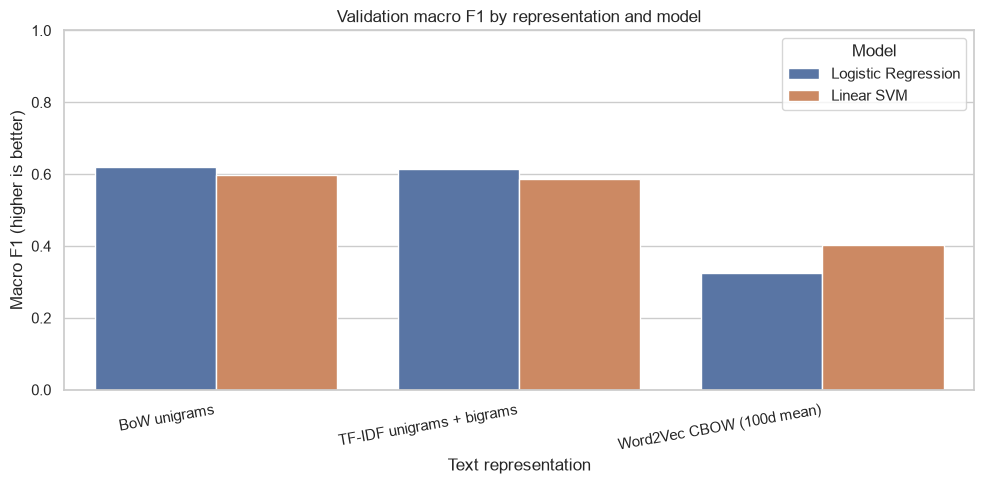

In [63]:
comparison_columns = [
    "Features", "Model", "Accuracy", "Precision (macro)", "Recall (macro)",
    "F1-score (macro)", "Precision (weighted)", "Recall (weighted)",
    "F1-score (weighted)",
]
results_df = pd.DataFrame(results).sort_values(
    "F1-score (macro)", ascending=False
).reset_index(drop=True)
display(results_df[comparison_columns].round(3))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=results_df, x="Features", y="F1-score (macro)", hue="Model", ax=ax
)
ax.set(title="Validation macro F1 by representation and model",
       xlabel="Text representation", ylabel="Macro F1 (higher is better)", ylim=(0, 1))
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()


## 7. Baseline comparison

Compare BoW, TF-IDF, and Word2Vec baselines on validation macro F1. Section 8 tunes the BoW and TF-IDF classifiers and compares all candidates on the same validation split.


In [64]:
best_result = results_df.iloc[0]
best_model_info = fitted_models[best_result["run_id"]]
print("Initial baseline model:", best_result["Features"], "+", best_result["Model"])
display(best_result[comparison_columns].to_frame("Validation score").round(3))


Initial baseline model: BoW unigrams + Logistic Regression


,Validation score
Features,BoW unigrams
Model,Logistic Regression
Accuracy,0.676471
Precision (macro),0.616602
Recall (macro),0.639772
F1-score (macro),0.6204
Precision (weighted),0.700325
Recall (weighted),0.676471
F1-score (weighted),0.684903


## 8. Hyperparameter tuning and model selection

Tune TF-IDF + Logistic Regression, BoW + Logistic Regression, TF-IDF + Linear SVM, and BoW + Linear SVM with stratified three-fold cross-validation on the TweetEval training split. The word-plus-character TF-IDF + Linear SVM candidate uses settings selected in a completed three-fold search, so this notebook does not repeat that search. Macro F1 is the selection metric because the emotion classes are imbalanced; accuracy, macro precision, and macro recall are reported as well. Compare all candidates on validation data.

The four searches in this notebook each test 60 randomly sampled configurations. The word-plus-character model uses the selected setting from a 16-configuration search: word unigrams, character n-grams from 2 to 5, character min_df of 4, equal feature weights, C=0.1, and balanced class weights. The held-out test split is evaluated after model selection.

### 8.1 Set up baselines and tuning settings

In [65]:
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.svm import LinearSVC
import sys
from pathlib import Path

WORKSPACE_ROOT = Path("D:/NLP-Lab")
if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))
from Project.cli.preprocessing import join_token_lists

# Reference configuration: TF-IDF unigrams+bigrams + balanced Logistic Regression.
baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True,
    )),
    ("classifier", LogisticRegression(
        C=1.0, max_iter=2000, class_weight="balanced",
        solver="lbfgs", random_state=42,
    )),
])
baseline_pipeline.fit(train_tokens, y_train)
baseline_val_predictions = baseline_pipeline.predict(val_tokens)
baseline_val_scores = metric_scores(y_val, baseline_val_predictions)

# Score all four requested metrics; select configurations by macro F1.
scoring = {
    "accuracy": "accuracy",
    "macro_precision": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "macro_recall": make_scorer(
        recall_score, average="macro", zero_division=0
    ),
    "macro_f1": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
}

# TF-IDF + Logistic Regression search.
search_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LogisticRegression(random_state=42)),
])
search_parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [None, 10000, 20000, 30000],
    "tfidf__min_df": [1, 2, 3, 5],
    "tfidf__max_df": [0.90, 0.95, 1.0],
    "tfidf__sublinear_tf": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"],
    "classifier__max_iter": [1000, 2000],
}

# TF-IDF + Linear SVM search.
svm_tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
])
svm_tfidf_parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [None, 10000, 20000, 30000],
    "tfidf__min_df": [1, 2, 3, 5],
    "tfidf__max_df": [0.90, 0.95, 1.0],
    "tfidf__sublinear_tf": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

# BoW + Linear SVM search.
svm_bow_pipeline = Pipeline([
    ("bow", CountVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
])
svm_bow_parameters = {
    "bow__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "bow__max_features": [None, 10000, 20000, 30000],
    "bow__min_df": [1, 2, 3, 5],
    "bow__max_df": [0.90, 0.95, 1.0],
    "bow__binary": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

cross_validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
tuning_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=search_parameters,
    n_iter=60, scoring=scoring, refit="macro_f1", cv=cross_validation,
    random_state=42, n_jobs=2, return_train_score=False, verbose=1,
)
svm_tfidf_search = RandomizedSearchCV(
    estimator=svm_tfidf_pipeline,
    param_distributions=svm_tfidf_parameters,
    n_iter=60, scoring=scoring, refit="macro_f1", cv=cross_validation,
    random_state=42, n_jobs=2, return_train_score=False, verbose=1,
)
svm_bow_search = RandomizedSearchCV(
    estimator=svm_bow_pipeline,
    param_distributions=svm_bow_parameters,
    n_iter=60, scoring=scoring, refit="macro_f1", cv=cross_validation,
    random_state=42, n_jobs=2, return_train_score=False, verbose=1,
)

# BoW + Logistic Regression search.
bow_lr_pipeline = Pipeline([
    ("bow", CountVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LogisticRegression(random_state=42)),
])
bow_lr_parameters = {
    "bow__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "bow__max_features": [None, 10000, 20000, 30000],
    "bow__min_df": [1, 2, 3, 5],
    "bow__max_df": [0.90, 0.95, 1.0],
    "bow__binary": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"],
    "classifier__max_iter": [1000, 2000],
}
bow_lr_search = RandomizedSearchCV(
    estimator=bow_lr_pipeline,
    param_distributions=bow_lr_parameters,
    n_iter=60, scoring=scoring, refit="macro_f1", cv=cross_validation,
    random_state=42, n_jobs=2, return_train_score=False, verbose=1,
)

# Use the best settings from the completed word-plus-character search. This
# notebook evaluates that configuration without repeating the tuning.
word_char_selected_parameters = {
    "features__word__ngram_range": (1, 1),
    "features__char__tfidf__ngram_range": (2, 5),
    "features__char__tfidf__min_df": 4,
    "features__transformer_weights": {"word": 1.0, "char": 1.0},
    "classifier__C": 0.1,
    "classifier__class_weight": "balanced",
}
word_char_pipeline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
            lowercase=False, max_features=30000, min_df=1, max_df=1.0,
        )),
        ("char", Pipeline([
            ("join_tokens", FunctionTransformer(join_token_lists, validate=False)),
            ("tfidf", TfidfVectorizer(
                analyzer="char_wb", lowercase=False, sublinear_tf=True,
            )),
        ])),
    ])),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
]).set_params(**word_char_selected_parameters)

print("Word-plus-character settings selected by the completed cross-validation search:")
display(pd.DataFrame([
    {"Hyperparameter": name, "Selected value": str(value)}
    for name, value in word_char_selected_parameters.items()
]))


Word-plus-character settings selected by the completed cross-validation search:


,Hyperparameter,Selected value
0,features__word__ngram_range,"(1, 1)"
1,features__char__tfidf__ngram_range,"(2, 5)"
2,features__char__tfidf__min_df,4
3,features__transformer_weights,"{'word': 1.0, 'char': 1.0}"
4,classifier__C,0.1
5,classifier__class_weight,balanced


### 8.2 Run the cross-validation searches

In [66]:
# Tune the four BoW/word-level TF-IDF classifier combinations on training data.
tuning_search.fit(train_tokens, y_train)
bow_lr_search.fit(train_tokens, y_train)
svm_tfidf_search.fit(train_tokens, y_train)
svm_bow_search.fit(train_tokens, y_train)

def top_trials(search, vectorizer_step, representation):
    cv_frame = pd.DataFrame(search.cv_results_)
    top_rows = cv_frame.sort_values("rank_test_macro_f1").head(10)
    parameters = pd.DataFrame(top_rows["params"].tolist(), index=top_rows.index)
    table = pd.DataFrame({
        "CV rank": top_rows["rank_test_macro_f1"].astype(int).to_numpy(),
        "CV accuracy": top_rows["mean_test_accuracy"].to_numpy(),
        "CV macro precision": top_rows["mean_test_macro_precision"].to_numpy(),
        "CV macro recall": top_rows["mean_test_macro_recall"].to_numpy(),
        "CV macro F1": top_rows["mean_test_macro_f1"].to_numpy(),
        "n-grams": parameters[f"{vectorizer_step}__ngram_range"].astype(str).to_numpy(),
        "max_features": parameters[f"{vectorizer_step}__max_features"].map(
            lambda value: "None" if pd.isna(value) else int(value)
        ).to_numpy(),
        "min_df": parameters[f"{vectorizer_step}__min_df"].to_numpy(),
        "max_df": parameters[f"{vectorizer_step}__max_df"].to_numpy(),
        "C": parameters["classifier__C"].to_numpy(),
        "class_weight": parameters["classifier__class_weight"].map(
            lambda value: "None" if value is None or pd.isna(value) else value
        ).to_numpy(),
    })
    if representation == "TF-IDF":
        table["sublinear_tf"] = parameters["tfidf__sublinear_tf"].to_numpy()
    else:
        table["binary"] = parameters["bow__binary"].to_numpy()
    return cv_frame, table

cv_results, top_tuning_trials = top_trials(tuning_search, "tfidf", "TF-IDF")
bow_lr_cv_results, bow_lr_top_trials = top_trials(
    bow_lr_search, "bow", "BoW"
)
svm_tfidf_cv_results, svm_tfidf_top_trials = top_trials(
    svm_tfidf_search, "tfidf", "TF-IDF"
)
svm_bow_cv_results, svm_bow_top_trials = top_trials(
    svm_bow_search, "bow", "BoW"
)

print("Top TF-IDF + Logistic Regression CV trials:")
display(top_tuning_trials.round(3).reset_index(drop=True))
print("Best CV macro F1:", round(tuning_search.best_score_, 3))

print("Top BoW + Logistic Regression CV trials:")
display(bow_lr_top_trials.round(3).reset_index(drop=True))
print("Best CV macro F1:", round(bow_lr_search.best_score_, 3))

print("Top TF-IDF + Linear SVM CV trials:")
display(svm_tfidf_top_trials.round(3).reset_index(drop=True))
print("Best CV macro F1:", round(svm_tfidf_search.best_score_, 3))

print("Top BoW + Linear SVM CV trials:")
display(svm_bow_top_trials.round(3).reset_index(drop=True))
print("Best CV macro F1:", round(svm_bow_search.best_score_, 3))


Fitting 3 folds for each of 60 candidates, totalling 180 fits


Fitting 3 folds for each of 60 candidates, totalling 180 fits
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Top TF-IDF + Logistic Regression CV trials:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,C,class_weight,sublinear_tf
0,1,0.699,0.655,0.630,0.639,"(1, 3)",None,1,1.00,1,balanced,False
1,2,0.692,0.638,0.639,0.638,"(1, 3)",10000,1,0.90,1,balanced,True
2,3,0.700,0.671,0.621,0.638,"(1, 2)",30000,1,0.90,100,balanced,True
3,4,0.691,0.635,0.641,0.637,"(1, 2)",10000,2,0.95,1,balanced,False
4,5,0.692,0.640,0.633,0.636,"(1, 2)",10000,2,1.00,10,balanced,True
5,6,0.701,0.693,0.612,0.635,"(1, 2)",20000,1,0.90,100,None,True
6,7,0.693,0.636,0.634,0.635,"(1, 1)",30000,2,0.90,10,balanced,False
7,8,0.678,0.623,0.642,0.629,"(1, 3)",30000,5,1.00,1,balanced,True
8,9,0.702,0.709,0.603,0.628,"(1, 2)",None,1,0.95,10,None,True
9,10,0.682,0.623,0.637,0.627,"(1, 1)",30000,3,0.90,1,balanced,False


Best CV macro F1: 0.639
Top BoW + Logistic Regression CV trials:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,C,class_weight,binary
0,1,0.690,0.636,0.635,0.635,"(1, 3)",30000,2,1.00,1.0,balanced,False
1,2,0.691,0.641,0.627,0.633,"(1, 3)",10000,1,1.00,1.0,balanced,False
2,3,0.686,0.632,0.633,0.631,"(1, 3)",10000,1,0.90,0.1,balanced,True
3,4,0.696,0.659,0.615,0.629,"(1, 1)",None,1,1.00,10.0,None,True
4,4,0.696,0.659,0.615,0.629,"(1, 1)",None,1,0.95,10.0,None,True
5,6,0.696,0.651,0.617,0.629,"(1, 3)",20000,1,0.90,1.0,balanced,False
6,7,0.686,0.630,0.625,0.627,"(1, 1)",20000,1,1.00,100.0,balanced,True
7,8,0.681,0.629,0.627,0.626,"(1, 2)",10000,1,1.00,0.1,balanced,False
8,9,0.682,0.624,0.632,0.626,"(1, 1)",10000,1,1.00,0.1,balanced,True
9,10,0.692,0.633,0.620,0.626,"(1, 2)",20000,1,0.95,100.0,balanced,True


Best CV macro F1: 0.635
Top TF-IDF + Linear SVM CV trials:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,C,class_weight,sublinear_tf
0,1,0.703,0.662,0.630,0.642,"(1, 2)",30000,2,0.90,0.1,balanced,True
1,2,0.703,0.670,0.625,0.641,"(1, 2)",20000,1,0.95,1.0,balanced,False
2,3,0.703,0.654,0.632,0.640,"(1, 3)",30000,3,0.90,0.1,balanced,False
3,4,0.704,0.674,0.623,0.640,"(1, 3)",30000,1,0.90,1.0,balanced,True
4,5,0.698,0.655,0.629,0.639,"(1, 3)",10000,1,0.95,1.0,balanced,False
5,6,0.702,0.652,0.631,0.639,"(1, 2)",10000,3,1.00,0.1,balanced,False
6,7,0.695,0.644,0.632,0.637,"(1, 2)",10000,2,0.90,1.0,balanced,False
7,8,0.703,0.662,0.622,0.636,"(1, 1)",30000,1,1.00,0.1,balanced,False
8,9,0.702,0.679,0.614,0.635,"(1, 2)",20000,1,0.95,0.1,balanced,False
9,10,0.691,0.636,0.634,0.634,"(1, 3)",20000,3,0.95,1.0,balanced,True


Best CV macro F1: 0.642
Top BoW + Linear SVM CV trials:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,C,class_weight,binary
0,1,0.717,0.706,0.626,0.647,"(1, 2)",20000,3,0.90,0.10,None,True
1,2,0.717,0.706,0.625,0.646,"(1, 3)",None,3,0.95,0.10,None,True
2,3,0.705,0.650,0.642,0.645,"(1, 2)",20000,3,1.00,0.10,balanced,True
3,4,0.708,0.685,0.623,0.642,"(1, 2)",None,1,0.90,0.10,balanced,True
4,5,0.703,0.654,0.633,0.641,"(1, 1)",30000,1,0.90,0.10,balanced,True
5,6,0.711,0.694,0.620,0.639,"(1, 1)",None,2,0.90,0.10,None,True
6,6,0.711,0.694,0.620,0.639,"(1, 1)",None,2,0.95,0.10,None,True
7,8,0.700,0.675,0.616,0.634,"(1, 2)",20000,1,1.00,0.10,balanced,False
8,9,0.700,0.686,0.609,0.631,"(1, 3)",30000,5,0.95,0.10,None,False
9,10,0.695,0.680,0.609,0.631,"(1, 3)",20000,1,1.00,0.01,balanced,False


Best CV macro F1: 0.647


### 8.3 Compare candidates on validation and select the model

Compare the top cross-validation candidates and the fixed word-plus-character candidate from the completed search on the same validation split. Select the highest macro F1. The test split is evaluated after model selection.


In [67]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

def evaluate_top_cv_candidates(cv_frame, pipeline):
    shortlist = cv_frame.sort_values("rank_test_macro_f1").head(20)
    candidate_models = []
    candidate_scores = []
    candidate_parameters = []
    for candidate_params in shortlist["params"]:
        candidate_model = clone(pipeline).set_params(**candidate_params)
        candidate_model.fit(train_tokens, y_train)
        candidate_predictions = candidate_model.predict(val_tokens)
        candidate_models.append(candidate_model)
        candidate_scores.append(metric_scores(y_val, candidate_predictions))
        candidate_parameters.append(candidate_params)

    best_index = max(
        range(len(candidate_scores)),
        key=lambda index: candidate_scores[index]["F1-score (macro)"],
    )
    table = pd.DataFrame([
        {"CV rank": int(shortlist.iloc[index]["rank_test_macro_f1"]), **scores}
        for index, scores in enumerate(candidate_scores)
    ]).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
    return {
        "scores": candidate_scores[best_index],
        "parameters": candidate_parameters[best_index],
        "pipeline": candidate_models[best_index],
        "table": table,
    }

lr_validation = evaluate_top_cv_candidates(cv_results, search_pipeline)
bow_lr_validation = evaluate_top_cv_candidates(
    bow_lr_cv_results, bow_lr_pipeline
)
svm_tfidf_validation = evaluate_top_cv_candidates(
    svm_tfidf_cv_results, svm_tfidf_pipeline
)
svm_bow_validation = evaluate_top_cv_candidates(
    svm_bow_cv_results, svm_bow_pipeline
)
# Fit the configuration selected in the completed cross-validation search on training data
# and evaluate it on the same validation split as the other candidates.
word_char_model = clone(word_char_pipeline).fit(train_tokens, y_train)
word_char_val_predictions = word_char_model.predict(val_tokens)
word_char_validation = {
    "scores": metric_scores(y_val, word_char_val_predictions),
    "parameters": word_char_selected_parameters,
    "pipeline": word_char_model,
}

for name, candidate in (
    ("TF-IDF + Logistic Regression", lr_validation),
    ("BoW + Logistic Regression", bow_lr_validation),
    ("TF-IDF + Linear SVM", svm_tfidf_validation),
    ("BoW + Linear SVM", svm_bow_validation),
):
    print(f"Top {name} candidates on validation:")
    display(candidate["table"][[
        "CV rank", "Accuracy", "Precision (macro)",
        "Recall (macro)", "F1-score (macro)",
    ]].head(10).round(3))

print("Word + character TF-IDF + Linear SVM on validation:")
display(pd.DataFrame([word_char_validation["scores"]]).round(3))

# Include every baseline from Section 5 in the final validation comparison.
metric_columns = [
    "Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"
]
model_options = {}
comparison_rows = []
for row in results_df.to_dict("records"):
    model_name = f"{row['Features']} + {row['Model']}"
    model_options[model_name] = fitted_models[row["run_id"]]
    comparison_rows.append({
        "Model": model_name,
        **{metric: row[metric] for metric in metric_columns},
    })

tuned_candidates = [
    ("Tuned TF-IDF + Logistic Regression", lr_validation),
    ("Tuned BoW + Logistic Regression", bow_lr_validation),
    ("Tuned TF-IDF + Linear SVM", svm_tfidf_validation),
    ("Tuned BoW + Linear SVM", svm_bow_validation),
    ("Tuned Word + Character TF-IDF + Linear SVM", word_char_validation),
]
for model_name, candidate in tuned_candidates:
    model_options[model_name] = {
        "kind": "pipeline", "pipeline": candidate["pipeline"]
    }
    comparison_rows.append({
        "Model": model_name,
        **{metric: candidate["scores"][metric] for metric in metric_columns},
    })

validation_model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "F1-score (macro)", ascending=False
).reset_index(drop=True)
print("Validation comparison: classical baselines and tuned finalists")
display(validation_model_comparison[["Model", *metric_columns]].round(3))

selected_model_name = validation_model_comparison.iloc[0]["Model"]
best_model_info = model_options[selected_model_name]
selected_train_predictions = best_model_info["pipeline"].predict(train_tokens)
selected_val_predictions = best_model_info["pipeline"].predict(val_tokens)
training_accuracy = accuracy_score(y_train, selected_train_predictions)
validation_accuracy = accuracy_score(y_val, selected_val_predictions)
print("Final model selected using validation macro F1:", selected_model_name)
print(f"Training accuracy (in-sample): {training_accuracy:.3f}")
print(f"Validation accuracy: {validation_accuracy:.3f}")


Top TF-IDF + Logistic Regression candidates on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,1,0.690,0.623,0.633,0.627
1,2,0.671,0.611,0.639,0.619
2,3,0.684,0.626,0.604,0.612
3,10,0.666,0.606,0.636,0.611
4,4,0.660,0.601,0.630,0.608
5,13,0.655,0.596,0.623,0.603
6,18,0.650,0.595,0.629,0.602
7,17,0.650,0.593,0.617,0.599
8,8,0.652,0.594,0.627,0.598
9,7,0.660,0.603,0.611,0.598


Top BoW + Logistic Regression candidates on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,1,0.676,0.612,0.625,0.614
1,2,0.671,0.608,0.618,0.609
2,18,0.666,0.608,0.628,0.609
3,6,0.666,0.603,0.608,0.605
4,15,0.647,0.595,0.629,0.598
5,8,0.647,0.590,0.618,0.597
6,13,0.674,0.638,0.579,0.597
7,12,0.674,0.616,0.580,0.592
8,14,0.636,0.585,0.619,0.589
9,9,0.634,0.578,0.610,0.586


Top TF-IDF + Linear SVM candidates on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,8,0.706,0.638,0.626,0.629
1,3,0.690,0.630,0.631,0.628
2,6,0.684,0.623,0.620,0.619
3,18,0.690,0.637,0.605,0.617
4,18,0.690,0.637,0.605,0.617
5,18,0.690,0.637,0.605,0.617
6,9,0.676,0.622,0.608,0.613
7,1,0.679,0.617,0.613,0.612
8,13,0.663,0.607,0.621,0.608
9,11,0.660,0.605,0.620,0.606


... (3 outputs left out)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Precision (weighted),Recall (weighted),F1-score (weighted)
0,0.719,0.656,0.66,0.655,0.725,0.719,0.72


Validation comparison: classical baselines and tuned finalists


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Tuned Word + Character TF-IDF + Linear SVM,0.719,0.656,0.660,0.655
1,Tuned TF-IDF + Linear SVM,0.706,0.638,0.626,0.629
2,Tuned TF-IDF + Logistic Regression,0.690,0.623,0.633,0.627
3,BoW unigrams + Logistic Regression,0.676,0.617,0.640,0.620
4,Tuned BoW + Linear SVM,0.679,0.616,0.629,0.618
5,Tuned BoW + Logistic Regression,0.676,0.612,0.625,0.614
6,TF-IDF unigrams + bigrams + Logistic Regression,0.668,0.608,0.635,0.614
7,BoW unigrams + Linear SVM,0.666,0.603,0.600,0.597
8,TF-IDF unigrams + bigrams + Linear SVM,0.663,0.595,0.588,0.588
9,Word2Vec CBOW (100d mean) + Linear SVM,0.540,0.449,0.404,0.402


Final model selected using validation macro F1: Tuned Word + Character TF-IDF + Linear SVM
Training accuracy (in-sample): 0.944
Validation accuracy: 0.719


### Validation model comparison

Macro F1 gives each emotion equal weight, so it is the main measure used to select the model. The comparison uses validation results only; test results do not affect this ranking. The word-plus-character candidate uses parameters already selected by cross-validation.


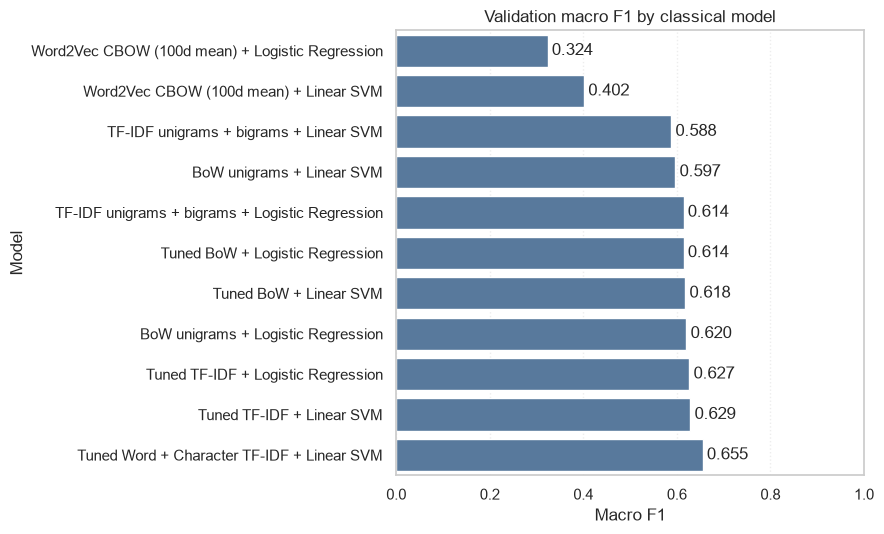

In [68]:
validation_f1 = validation_model_comparison.set_index("Model")[
    "F1-score (macro)"
].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(
    x=validation_f1.values,
    y=validation_f1.index,
    color="#4C78A8",
    ax=ax,
)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set(
    title="Validation macro F1 by classical model",
    xlabel="Macro F1",
    ylabel="Model",
    xlim=(0, 1),
)
ax.grid(axis="x", linestyle=":", alpha=0.35)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


### 8.4 Prepare the selected model for calibration

Accuracy is reported for the training, validation, and test splits. Training accuracy is in-sample; validation and test use separate splits. The selected model is refit on training plus validation before the final test evaluation.


In [69]:
# Prepare the development data used to fit and calibrate the validation winner.
import numpy as np

final_training_tokens = train_tokens + val_tokens
final_training_labels = np.concatenate([y_train, y_val])
print("Selected model:", selected_model_name)
print("Development rows prepared for final fitting and calibration:", len(final_training_labels))


Selected model: Tuned Word + Character TF-IDF + Linear SVM
Development rows prepared for final fitting and calibration: 3606


### 8.5 Export the selected model for the CLI

Save the selected pipeline and preprocessing settings used by the command-line app. The export cell calibrates the SVM on the combined training and validation data.


In [70]:
# Calibrate and export the validation-selected Linear SVM pipeline for the CLI.
# LinearSVC has no predict_proba method, so use sigmoid calibration on development data.
import joblib
import sys
from pathlib import Path
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

# Fixed paths for this notebook and the CLI artifact.
WORKSPACE_ROOT = Path("D:/NLP-Lab")
CLI_DIR = WORKSPACE_ROOT / "Project" / "cli"
MODEL_PATH = CLI_DIR / "emotion_model.joblib"

if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))
from Project.cli.preprocessing import identity_tokenizer as cli_identity_tokenizer

inference_pipeline = best_model_info["pipeline"]
# Keep tokenizer callables importable when joblib loads the saved artifact.
for step in inference_pipeline.named_steps.values():
    if hasattr(step, "tokenizer"):
        step.tokenizer = cli_identity_tokenizer
    if hasattr(step, "transformer_list"):
        for _, transformer in step.transformer_list:
            if hasattr(transformer, "tokenizer"):
                transformer.tokenizer = cli_identity_tokenizer
# Each fold fits the pipeline on its training rows and calibrates on held-out rows.
probability_model = CalibratedClassifierCV(
    estimator=clone(inference_pipeline), method="sigmoid", cv=3, ensemble=True
)
probability_model.fit(final_training_tokens, final_training_labels)
best_model_info = {"kind": "pipeline", "pipeline": probability_model}

model_bundle = {
    "kind": "pipeline",
    "remove_stopwords": selected_token_column == "tokens_no_stopwords",
    "lemmatize": selected_token_column != "tokens_unlemmatized",
    "emotion_labels": emotion_labels,
    "classes": list(emotion_labels.keys()),
    "model": probability_model,
}

CLI_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(model_bundle, MODEL_PATH)
print("Saved model:", MODEL_PATH)


Saved model: D:\NLP-Lab\Project\cli\emotion_model.joblib


## 9. Final test evaluation

Refit the validation winner on the combined training and validation splits. Evaluate it once on the official test split; use those results as the final performance estimate.


Test accuracy: 0.745
              precision    recall  f1-score   support

       anger      0.744     0.869     0.802       558
         joy      0.741     0.735     0.738       358
    optimism      0.691     0.309     0.427       123
     sadness      0.758     0.712     0.734       382

    accuracy                          0.745      1421
   macro avg      0.733     0.656     0.675      1421
weighted avg      0.742     0.745     0.735      1421



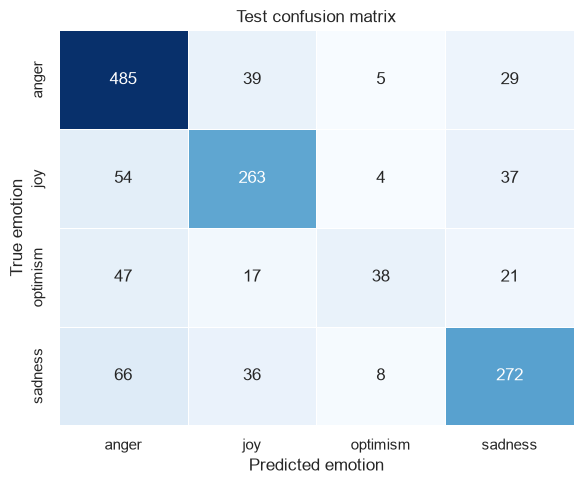

In [71]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_tokens = test_df[selected_token_column].tolist()
test_predictions = best_model_info["pipeline"].predict(test_tokens)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test accuracy: {test_accuracy:.3f}")
print(classification_report(
    y_test, test_predictions, labels=list(emotion_labels),
    target_names=label_names, digits=3, zero_division=0,
))

confusion_values = confusion_matrix(
    y_test, test_predictions, labels=list(emotion_labels)
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    confusion_values, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=label_names, yticklabels=label_names, linewidths=0.5, ax=ax,
)
ax.set(title="Test confusion matrix", xlabel="Predicted emotion", ylabel="True emotion")
fig.tight_layout()
display(fig)
plt.close(fig)


### Misclassified test tweets

Show up test tweets the selected model predicted incorrectly.


In [72]:
error_mask = test_predictions != y_test
error_table = test_df.loc[error_mask, ["text", "emotion"]].rename(
    columns={"text": "Tweet", "emotion": "True emotion"}
).copy()
error_table["Predicted emotion"] = [
    emotion_labels[int(label)] for label in test_predictions[error_mask]
]

print(f"Misclassified test tweets: {error_mask.sum()} / {len(test_df)}")
display(error_table.head(20))


Misclassified test tweets: 363 / 1421


,Tweet,True emotion,Predicted emotion
8,@user @user #cmbyn does screen August 4 &amp;...,sadness,joy
15,@user #shocking loss of talented young man#pra...,sadness,anger
23,@user @user Americans do not spank their child...,optimism,anger
25,Favorite character who's name starts with the ...,joy,anger
26,I'm so nervous I could puke + my body temp is ...,joy,sadness
30,@user Is it just me that thinks it looks boring?,sadness,anger
36,"@user No #racism, no #hatred , no #sectarianis...",optimism,anger
37,sleep is and will always be one of the best re...,optimism,sadness
39,yukwon no video do zico the world is shaking,sadness,joy
40,"BUT, I have offended so many people with the i...",optimism,anger


## 10. Documentation

This analysis uses the official TweetEval emotion train, validation, and test splits from Hugging Face. The training split contained 25 exact duplicate tweets, which were removed before modeling. No exact tweet text overlapped across train, validation, and test. Preprocessing and model settings are chosen using training cross-validation and validation data, and the test split is evaluated after model selection.

Preprocessing converts common contractions, emoji, emoticons, hashtags, and expressive punctuation into features; removes URLs and mentions; normalizes repeated characters; and applies POS-aware WordNet lemmatization. Validation selected lemmatization with stopword removal while retaining negation and other emotion-bearing words.

All classifier and Word2Vec training uses TweetEval data. This notebook tunes four BoW and word-level TF-IDF classifier combinations with three-fold cross-validation and compares their finalists with a word-plus-character TF-IDF + Linear SVM candidate. The combined model uses settings selected by a completed 16-configuration, three-fold search; its search is not repeated here. Validation macro F1 selects the model, which is refit and calibrated on the combined training and validation splits before test evaluation. Individual predictions can still be wrong, and the displayed percentages are estimates rather than certainty. Final metrics are reported in Sections 8 and 9.